# A/B Test Analysis: "Conversation Starters" in a Dating App

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated dataset of a fictional dating app ("Driftly"). No real company data is used.

**Feature tested.** On the match screen, users see three suggested opening lines based on shared interests.
They can tap one to send it, edit it, or ignore it.

**Hypothesis.** The blank first message is the biggest drop-off between *Match* and *Conversation*.
Suggested openers lower that friction, so more matches turn into conversations that get a reply.

**Pre-registered metrics**

| Role | Metric | Unit |
|---|---|---|
| Primary | Conversations with a reply per user (7 days) | user |
| Diagnostic | First-message rate = first messages / matches | match |
| Diagnostic | Reply rate = replied conversations / first messages | message |
| Guardrail | D7 retention | user |
| Guardrail | Reports per 1,000 first messages | message |
| Guardrail | Premium purchase within 7 days | user |

**Design.** 50/50 user-level randomisation, 14-day enrollment, 7-day observation window per user, α = 0.05 (two-sided).

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
users = pd.read_csv("data/users.csv.gz")
daily = pd.read_csv("data/daily_activity.csv.gz")
users["treat"] = (users.group == "treatment").astype(int)
users.head()

,user_id,group,gender,platform,user_type,enroll_date,pre_replied_convs_28d,matches_7d,first_messages_7d,conversations_with_reply_7d,reports_received_7d,retained_d7,premium_purchase_7d,treat
0,100001,treatment,male,android,new,2026-09-09,NaN,2,2,0,0,0,0,1
1,100002,control,female,ios,existing,2026-09-11,11.0000,10,2,0,0,0,0,0
2,100003,control,female,ios,existing,2026-09-14,4.0000,12,0,0,0,0,0,0
3,100004,control,male,ios,existing,2026-09-12,7.0000,1,1,1,0,0,0,0
4,100005,control,male,ios,existing,2026-09-03,10.0000,3,1,1,0,1,0,0


## 1. Sanity checks
### 1.1 Sample ratio mismatch (SRM)

In [2]:
counts = users.group.value_counts().reindex(["control", "treatment"])
chi2, p_srm = stats.chisquare(counts, f_exp=[len(users) / 2] * 2)
print(counts.to_dict(), f"chi2={chi2:.2f}, p={p_srm:.3f}")
print("SRM check:", "PASS" if p_srm > 0.001 else "FAIL - stop and investigate assignment")

{'control': 40255, 'treatment': 39745} chi2=3.25, p=0.071
SRM check: PASS


### 1.2 Balance of pre-treatment covariates

In [3]:
bal = pd.concat([
    pd.crosstab(users.group, users.gender, normalize="index"),
    pd.crosstab(users.group, users.platform, normalize="index"),
    pd.crosstab(users.group, users.user_type, normalize="index"),
    users.groupby("group")[["pre_replied_convs_28d"]].mean(),
], axis=1)
bal

,female,male,android,ios,existing,new,pre_replied_convs_28d
group,,,,,,,
control,0.3787,0.6213,0.4482,0.5518,0.6506,0.3494,9.8971
treatment,0.3794,0.6206,0.4478,0.5522,0.6503,0.3497,9.8927


### 1.3 Power: what effect could we detect?
Minimum detectable effect for the primary metric at 80% power, with and without CUPED variance reduction
(covariate = replied conversations in the 28 days before the test; new users get 0 plus a new-user flag).

In [4]:
y = users.conversations_with_reply_7d
n_arm = len(users) / 2
mde_d = TTestIndPower().solve_power(nobs1=n_arm, alpha=0.05, power=0.8, ratio=1.0)
ctrl = users[users.treat == 0]
mde_abs = mde_d * ctrl.conversations_with_reply_7d.std()
print(f"MDE (no CUPED): {mde_abs:.4f} conv/user = {mde_abs / ctrl.conversations_with_reply_7d.mean():.1%} relative")

users["pre_filled"] = users.pre_replied_convs_28d.fillna(0)
users["is_new"] = (users.user_type == "new").astype(int)
r2 = smf.ols("conversations_with_reply_7d ~ pre_filled + is_new + C(gender)", data=ctrl.assign(
    pre_filled=ctrl.pre_replied_convs_28d.fillna(0), is_new=(ctrl.user_type == "new").astype(int))).fit().rsquared
print(f"CUPED variance reduction: {r2:.1%} -> MDE {mde_abs * np.sqrt(1 - r2) / ctrl.conversations_with_reply_7d.mean():.1%} relative")

MDE (no CUPED): 0.0189 conv/user = 3.2% relative
CUPED variance reduction: 18.1% -> MDE 2.9% relative


## 2. Results
Helpers: user-level means use Welch's t-test; ratio metrics (per match / per message) use the **delta method**,
because matches inside one user are not independent and a naive per-match test understates the variance.
Relative lifts get delta-method CIs for a ratio of two means.

In [5]:
def ratio_stats(num, den):
    """mean ratio sum(num)/sum(den) and its delta-method variance (user-level clustering)."""
    n = len(num); mx, my = den.mean(), num.mean()
    vx, vy = den.var(ddof=1), num.var(ddof=1); cxy = np.cov(num, den, ddof=1)[0, 1]
    r = my / mx
    var = (vy / mx**2 - 2 * my * cxy / mx**3 + my**2 * vx / mx**4) / n
    return r, var

def compare(df, num, den=None, name=None):
    a, b = df[df.treat == 0], df[df.treat == 1]
    if den is None:
        ma, mb = a[num].mean(), b[num].mean()
        va, vb = a[num].var(ddof=1) / len(a), b[num].var(ddof=1) / len(b)
    else:
        ma, va = ratio_stats(a[num].values, a[den].values)
        mb, vb = ratio_stats(b[num].values, b[den].values)
    diff = mb - ma; se = np.sqrt(va + vb)
    rel = mb / ma - 1
    se_rel = np.sqrt(vb / ma**2 + mb**2 * va / ma**4)   # delta method for mb/ma
    p = 2 * stats.norm.sf(abs(diff / se))
    return dict(metric=name or num, control=ma, treatment=mb, abs_diff=diff,
                rel_lift=rel, rel_lo=rel - 1.96 * se_rel, rel_hi=rel + 1.96 * se_rel, p_value=p)

users["first_msgs_x1000"] = users.first_messages_7d / 1000   # for reports per 1k first messages
metrics = [
    ("conversations_with_reply_7d", None, "Primary: replied conversations / user"),
    ("first_messages_7d", "matches_7d", "First-message rate (per match)"),
    ("conversations_with_reply_7d", "first_messages_7d", "Reply rate (per first message)"),
    ("retained_d7", None, "Guardrail: D7 retention"),
    ("reports_received_7d", "first_msgs_x1000", "Guardrail: reports / 1k first messages"),
    ("premium_purchase_7d", None, "Guardrail: premium purchase 7d"),
]
overall = pd.DataFrame([compare(users, n, d, nm) for n, d, nm in metrics])
overall

,metric,control,treatment,abs_diff,rel_lift,rel_lo,rel_hi,p_value
0,Primary: replied conversations / user,0.5877,0.6628,0.0751,0.1278,0.1026,0.1530,0.0000
1,First-message rate (per match),0.2610,0.3008,0.0397,0.1522,0.1394,0.1651,0.0000
2,Reply rate (per first message),0.4452,0.4323,-0.0129,-0.0290,-0.0421,-0.0159,0.0000
3,Guardrail: D7 retention,0.3112,0.3138,0.0026,0.0083,-0.0124,0.0290,0.4305
4,Guardrail: reports / 1k first messages,2.7098,2.7734,0.0636,0.0235,-0.2058,0.2527,0.8391
5,Guardrail: premium purchase 7d,0.0352,0.0333,-0.0019,-0.0536,-0.1232,0.0161,0.1422


### 2.1 Primary metric with CUPED
Regression adjustment on pre-period behaviour: same estimand, tighter interval.

In [6]:
m_raw = smf.ols("conversations_with_reply_7d ~ treat", data=users).fit(cov_type="HC1")
m_cuped = smf.ols("conversations_with_reply_7d ~ treat + pre_filled + is_new + C(gender) + C(platform)",
                  data=users).fit(cov_type="HC1")
base = users.loc[users.treat == 0, "conversations_with_reply_7d"].mean()
for lbl, m in [("raw", m_raw), ("CUPED", m_cuped)]:
    est, (lo, hi) = m.params["treat"], m.conf_int().loc["treat"]
    print(f"{lbl:6s} lift = {est/base:+.1%}  95% CI [{lo/base:+.1%}, {hi/base:+.1%}]  SE={m.bse['treat']:.4f}")
print(f"SE reduction from CUPED: {1 - m_cuped.bse['treat'] / m_raw.bse['treat']:.0%}")

raw    lift = +12.8%  95% CI [+10.4%, +15.2%]  SE=0.0071
CUPED  lift = +12.8%  95% CI [+10.7%, +14.9%]  SE=0.0064
SE reduction from CUPED: 10%


### 2.2 The headline hides a split: who does the lift come from?
Segments are checked with **Holm correction** (6 tests), and the gender difference with a formal **interaction test**,
so the split is not a forking-paths artefact.

In [7]:
seg_rows = []
for col in ["gender", "platform", "user_type"]:
    for val in sorted(users[col].unique()):
        r = compare(users[users[col] == val], "conversations_with_reply_7d", None, f"{col} = {val}")
        r["n"] = int((users[col] == val).sum()); seg_rows.append(r)
seg = pd.DataFrame(seg_rows)
seg["p_holm"] = multipletests(seg.p_value, method="holm")[1]
display(seg[["metric", "n", "control", "treatment", "rel_lift", "rel_lo", "rel_hi", "p_value", "p_holm"]])

inter = smf.ols("conversations_with_reply_7d ~ treat * C(gender) + pre_filled + is_new + C(platform)",
                data=users).fit(cov_type="HC1")
p_inter = inter.pvalues["treat:C(gender)[T.male]"]
print(f"treatment x gender interaction p = {p_inter:.2g}")

,metric,n,control,treatment,rel_lift,rel_lo,rel_hi,p_value,p_holm
0,gender = female,30324,0.7720,0.9658,0.2510,0.2114,0.2905,0.0000,0.0000
1,gender = male,49676,0.4753,0.4776,0.0047,-0.0257,0.0351,0.7594,0.7594
2,platform = android,35841,0.5827,0.6589,0.1307,0.0928,0.1687,0.0000,0.0000
3,platform = ios,44159,0.5917,0.6659,0.1254,0.0917,0.1592,0.0000,0.0000
4,user_type = existing,52036,0.5911,0.6613,0.1187,0.0876,0.1498,0.0000,0.0000
5,user_type = new,27964,0.5813,0.6655,0.1450,0.1019,0.1881,0.0000,0.0000


treatment x gender interaction p = 1.1e-40


### 2.3 Mechanism: decompose the funnel by gender
Replied conversations per user = matches × first-message rate × reply rate.

In [8]:
funnel = []
for g in ["female", "male"]:
    d = users[users.gender == g]
    for n, den, nm in metrics[:3]:
        r = compare(d, n, den, nm); r["gender"] = g; funnel.append(r)
funnel = pd.DataFrame(funnel)
funnel[["gender", "metric", "control", "treatment", "rel_lift", "rel_lo", "rel_hi", "p_value"]]

,gender,metric,control,treatment,rel_lift,rel_lo,rel_hi,p_value
0,female,Primary: replied conversations / user,0.7720,0.9658,0.2510,0.2114,0.2905,0.0000
1,female,First-message rate (per match),0.1964,0.2410,0.2270,0.2076,0.2464,0.0000
2,female,Reply rate (per first message),0.4936,0.4976,0.0082,-0.0093,0.0256,0.3589
3,male,Primary: replied conversations / user,0.4753,0.4776,0.0047,-0.0257,0.0351,0.7594
4,male,First-message rate (per match),0.3565,0.3902,0.0945,0.0802,0.1088,0.0000
5,male,Reply rate (per first message),0.4058,0.3719,-0.0834,-0.1019,-0.0649,0.0000


**Reading.** Women: suggested openers lift the first-message rate by ~23% and reply rates hold, so the gain flows straight through to replied conversations.
Men: they also send more openers (+9%), but those openers get fewer replies (−8%), so the net effect is ~0.
Templated openers from men read as low-effort to the women receiving them.

### 2.4 Novelty check: does the effect fade?

In [9]:
d = daily.merge(users[["user_id", "treat", "gender"]], on="user_id")
nov = []
for g in ["female", "male"]:
    for day in range(7):
        sub_u = users[["user_id", "treat"]].copy()
        agg = d[(d.gender == g) & (d.day_since_enroll == day)].groupby("user_id")[["matches", "first_messages_sent"]].sum()
        sub = sub_u.merge(agg, left_on="user_id", right_index=True)
        r = compare(sub, "first_messages_sent", "matches", f"D{day}")
        r.update(gender=g, day=day); nov.append(r)
nov = pd.DataFrame(nov)
display(nov.pivot(index="day", columns="gender", values="rel_lift"))

# late-window (D4-D6) lift: closer to the steady state than the 7-day average
late = {}
for g in ["female", "male"]:
    agg = d[(d.gender == g) & (d.day_since_enroll >= 4)].groupby("user_id")[["matches", "first_messages_sent", "conversations_with_reply"]].sum()
    sub = users[["user_id", "treat"]].merge(agg, left_on="user_id", right_index=True)
    late[g] = dict(fmr=compare(sub, "first_messages_sent", "matches"),
                   reply=compare(sub, "conversations_with_reply", "first_messages_sent"))
    print(g, f"D4-D6 first-message rate lift {late[g]['fmr']['rel_lift']:+.1%} "
             f"[{late[g]['fmr']['rel_lo']:+.1%}, {late[g]['fmr']['rel_hi']:+.1%}]")

gender,female,male
day,,
0,0.3748,0.1884
1,0.2614,0.0964
2,0.2269,0.0944
3,0.1865,0.0868
4,0.1554,0.0433
5,0.1607,0.0548
6,0.1254,0.0377


female D4-D6 first-message rate lift +14.8% [+11.8%, +17.8%]
male D4-D6 first-message rate lift +4.5% [+2.3%, +6.8%]


Strong novelty effect. Women's first-message lift falls from ~+37% on D0 to ~+15% by D4–D6; men's from ~+19% to ~+5%.
So the 7-day average (+23% for women) **overstates** the lasting effect. Plan on the late-window level, and confirm it with a holdout.

## 3. Charts

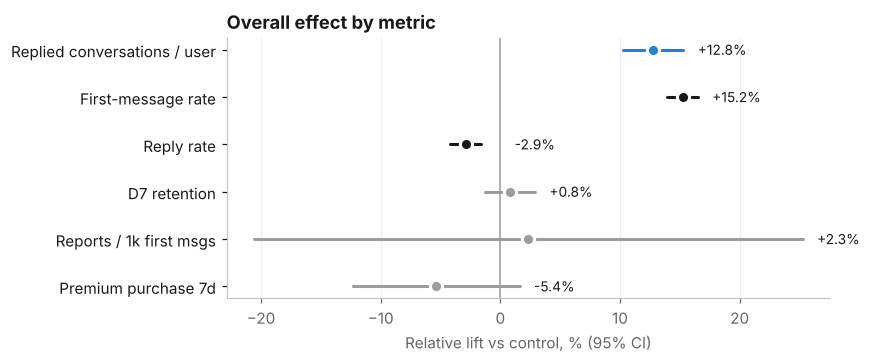

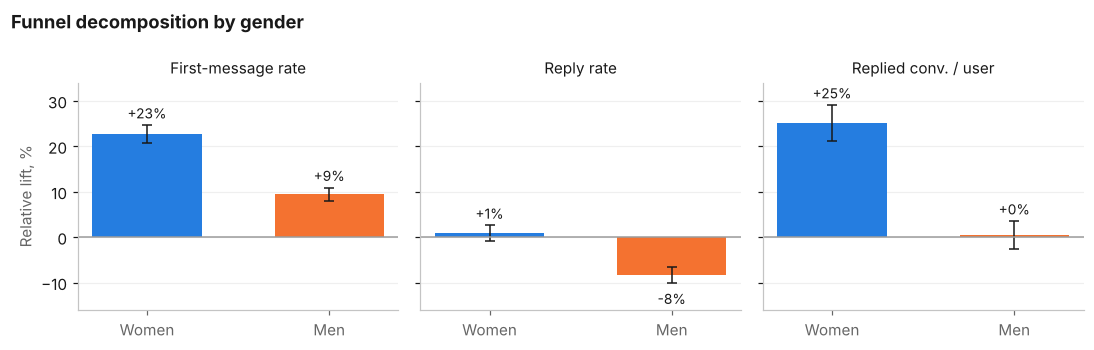

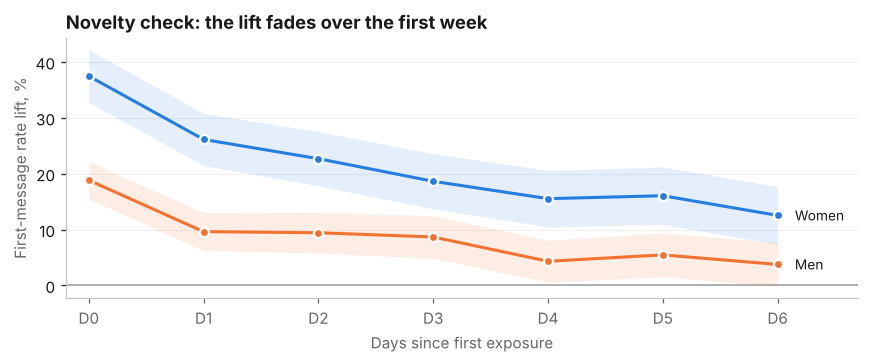

In [10]:
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#c4c4c4", "axes.labelcolor": "#666666",
                     "xtick.color": "#666666", "ytick.color": "#191919", "figure.dpi": 110})
BLUE, ORANGE, GRAY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"

def forest(ax, df, labels, colors):
    ys = np.arange(len(df))[::-1]
    for y, (_, r), c in zip(ys, df.iterrows(), colors):
        ax.plot([r.rel_lo * 100, r.rel_hi * 100], [y, y], color=c, lw=2, solid_capstyle="round")
        ax.plot(r.rel_lift * 100, y, "o", color=c, ms=8, mec="white", mew=2)
        ax.text(max(r.rel_hi * 100, 0) + 1.2, y, f"{r.rel_lift:+.1%}", va="center", color=INK, fontsize=9)
    ax.axvline(0, color=GRAY, lw=1)
    ax.set_yticks(ys, labels); ax.set_xlabel("Relative lift vs control, % (95% CI)")
    ax.grid(axis="x", color="#efefef"); ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(8, 3.4))
forest(ax, overall, ["Replied conversations / user", "First-message rate", "Reply rate",
                     "D7 retention", "Reports / 1k first msgs", "Premium purchase 7d"],
       [BLUE] + [INK] * 2 + [GRAY] * 3)
ax.set_title("Overall effect by metric", loc="left", fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig("charts/overall_forest.png", dpi=220)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
names = ["First-message rate", "Reply rate", "Replied conv. / user"]
for ax, nm, (n, den, full) in zip(axes, names, [metrics[1], metrics[2], metrics[0]]):
    sub = funnel[funnel.metric == full].set_index("gender").loc[["female", "male"]]
    for i, (g, r) in enumerate(sub.iterrows()):
        c = BLUE if g == "female" else ORANGE
        ax.bar(i, r.rel_lift * 100, color=c, width=0.6)
        ax.errorbar(i, r.rel_lift * 100, yerr=[[(r.rel_lift - r.rel_lo) * 100], [(r.rel_hi - r.rel_lift) * 100]],
                    color=INK, lw=1, capsize=3)
        ax.text(i, r.rel_hi * 100 + 1.5 if r.rel_lift >= 0 else r.rel_lo * 100 - 4.5,
                f"{r.rel_lift:+.0%}", ha="center", fontsize=9, color=INK)
    ax.axhline(0, color=GRAY, lw=1); ax.set_xticks([0, 1], ["Women", "Men"]); ax.set_title(nm, fontsize=10, color=INK)
    ax.set_ylim(-16, 34)
    ax.grid(axis="y", color="#efefef"); ax.set_axisbelow(True)
axes[0].set_ylabel("Relative lift, %")
fig.suptitle("Funnel decomposition by gender", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig("charts/funnel_by_gender.png", dpi=220)

fig, ax = plt.subplots(figsize=(8, 3.4))
for g, c, lab in [("female", BLUE, "Women"), ("male", ORANGE, "Men")]:
    s = nov[nov.gender == g]
    ax.fill_between(s.day, s.rel_lo * 100, s.rel_hi * 100, color=c, alpha=0.12, lw=0)
    ax.plot(s.day, s.rel_lift * 100, color=c, lw=2, marker="o", ms=6, mec="white", mew=1.5)
    ax.text(6.15, s.rel_lift.iloc[-1] * 100, lab, color=INK, va="center", fontsize=9)
ax.axhline(0, color=GRAY, lw=1); ax.set_xticks(range(7), [f"D{i}" for i in range(7)])
ax.set_xlabel("Days since first exposure"); ax.set_ylabel("First-message rate lift, %")
ax.set_xlim(-0.2, 6.7); ax.grid(axis="y", color="#efefef"); ax.set_axisbelow(True)
ax.set_title("Novelty check: the lift fades over the first week", loc="left", fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig("charts/novelty.png", dpi=220)
plt.show()

## 4. Decision

| Audience | Decision | Why |
|---|---|---|
| Women | **Ship, with a holdout** | Replied conversations/user +25% over 7 days, reply quality unchanged, guardrails flat. Novelty inflates the 7-day number: plan on roughly +15%, the D4–D6 level. |
| Men | **Don't ship this version, iterate** | More openers but fewer replies, so net ≈ 0. Next test: personalised or editable suggestions, nudge to edit before sending. |

**Caveats.** 7-day window, so the steady-state lift and long-term retention need a holdout (5% of women kept on control for 4–6 weeks).
Reports are a rare event, so this test can only rule out large increases.

In [11]:
out = dict(srm_p=p_srm, n=int(len(users)), n_control=int(counts["control"]), n_treatment=int(counts["treatment"]),
           overall=overall.to_dict("records"), segments=seg.to_dict("records"), funnel=funnel.to_dict("records"),
           novelty=nov.to_dict("records"), p_interaction=p_inter, late=late,
           cuped=dict(raw_lift=m_raw.params["treat"] / base, cuped_lift=m_cuped.params["treat"] / base,
                      cuped_lo=m_cuped.conf_int().loc["treat", 0] / base, cuped_hi=m_cuped.conf_int().loc["treat", 1] / base,
                      se_reduction=1 - m_cuped.bse["treat"] / m_raw.bse["treat"]))
json.dump(out, open("results.json", "w"), default=float, indent=1)